# Comparativo cinza × B × S

O mesmo pipeline (Otsu + pós-processamento) nos 3 canais candidatos — com a polaridade certa de cada um.


In [1]:
import sys
from pathlib import Path

# O kernel inicia na pasta DESTE caderno — localiza a raiz do projeto:
RAIZ = Path.cwd()
if not (RAIZ / "src" / "leitura.py").exists():
    RAIZ = RAIZ.parent          # kernel começou dentro de notebooks/
sys.path.insert(0, str(RAIZ))   # raiz no path -> 'from src...' funciona

# Imports padrão de todos os cadernos:
from src.leitura import (PASTA_IMAGENS, PASTA_RESULTADOS, carregar_imagem,
                         nome_da_mascara, criar_pastas_resultados, auditar_base)
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("raiz do projeto:", RAIZ)

raiz do projeto: /home/isadora/Documentos/ProcessIMg


In [2]:
from src.preprocessamento import para_cinza, para_hsv
from src.segmentacao import binarizar, otsu, sobrepor
from src.morfologia import pos_processar

CANAIS = {
    "cinza": lambda img: para_cinza(img),           # lesão escura  -> invertida
    "B":     lambda img: img[:, :, 2],               # lesão escura  -> invertida
    "S":     lambda img: para_hsv(img)[:, :, 1],     # lesão CLARA   -> polaridade padrão
}
INVERTIDA = {"cinza": True, "B": True, "S": False}
IMAGENS = ["ISIC_0010206.jpg", "ISIC_0012940.jpg", "ISIC_0010104.jpg", "PH2_IMD057.bmp"]

In [3]:
print(f"{'imagem':<16} {'canal':>6} {'t*':>5} {'% máscara':>10} {'objetos':>8}")
for nome in IMAGENS:
    img = carregar_imagem(PASTA_IMAGENS / nome)
    nome_curto = Path(nome).stem
    for canal, extrair in CANAIS.items():
        plano = extrair(img)
        t = otsu(plano)
        bruta = binarizar(plano, t, invertida=INVERTIDA[canal])
        final = pos_processar(bruta)
        n_obj = cv2.connectedComponentsWithStats(bruta, 8)[0] - 1
        frac = final.mean() / 255
        print(f"{nome_curto:<16} {canal:>6} {t:>5} {frac*100:>9.1f}% {n_obj:>8}")

imagem            canal    t*  % máscara  objetos
ISIC_0010206      cinza   168       5.9%        6
ISIC_0010206          B   144       6.6%        3
ISIC_0010206          S    77       7.0%        3
ISIC_0012940      cinza   169      93.9%    10351
ISIC_0012940          B   150      56.7%     7347
ISIC_0012940          S    65      94.8%     4760
ISIC_0010104      cinza   204      12.0%     1170
ISIC_0010104          B   184      12.4%      844
ISIC_0010104          S    64       5.6%      405
PH2_IMD057        cinza   123      37.9%      284
PH2_IMD057            B   106      39.8%      395
PH2_IMD057            S    93      42.4%     2841


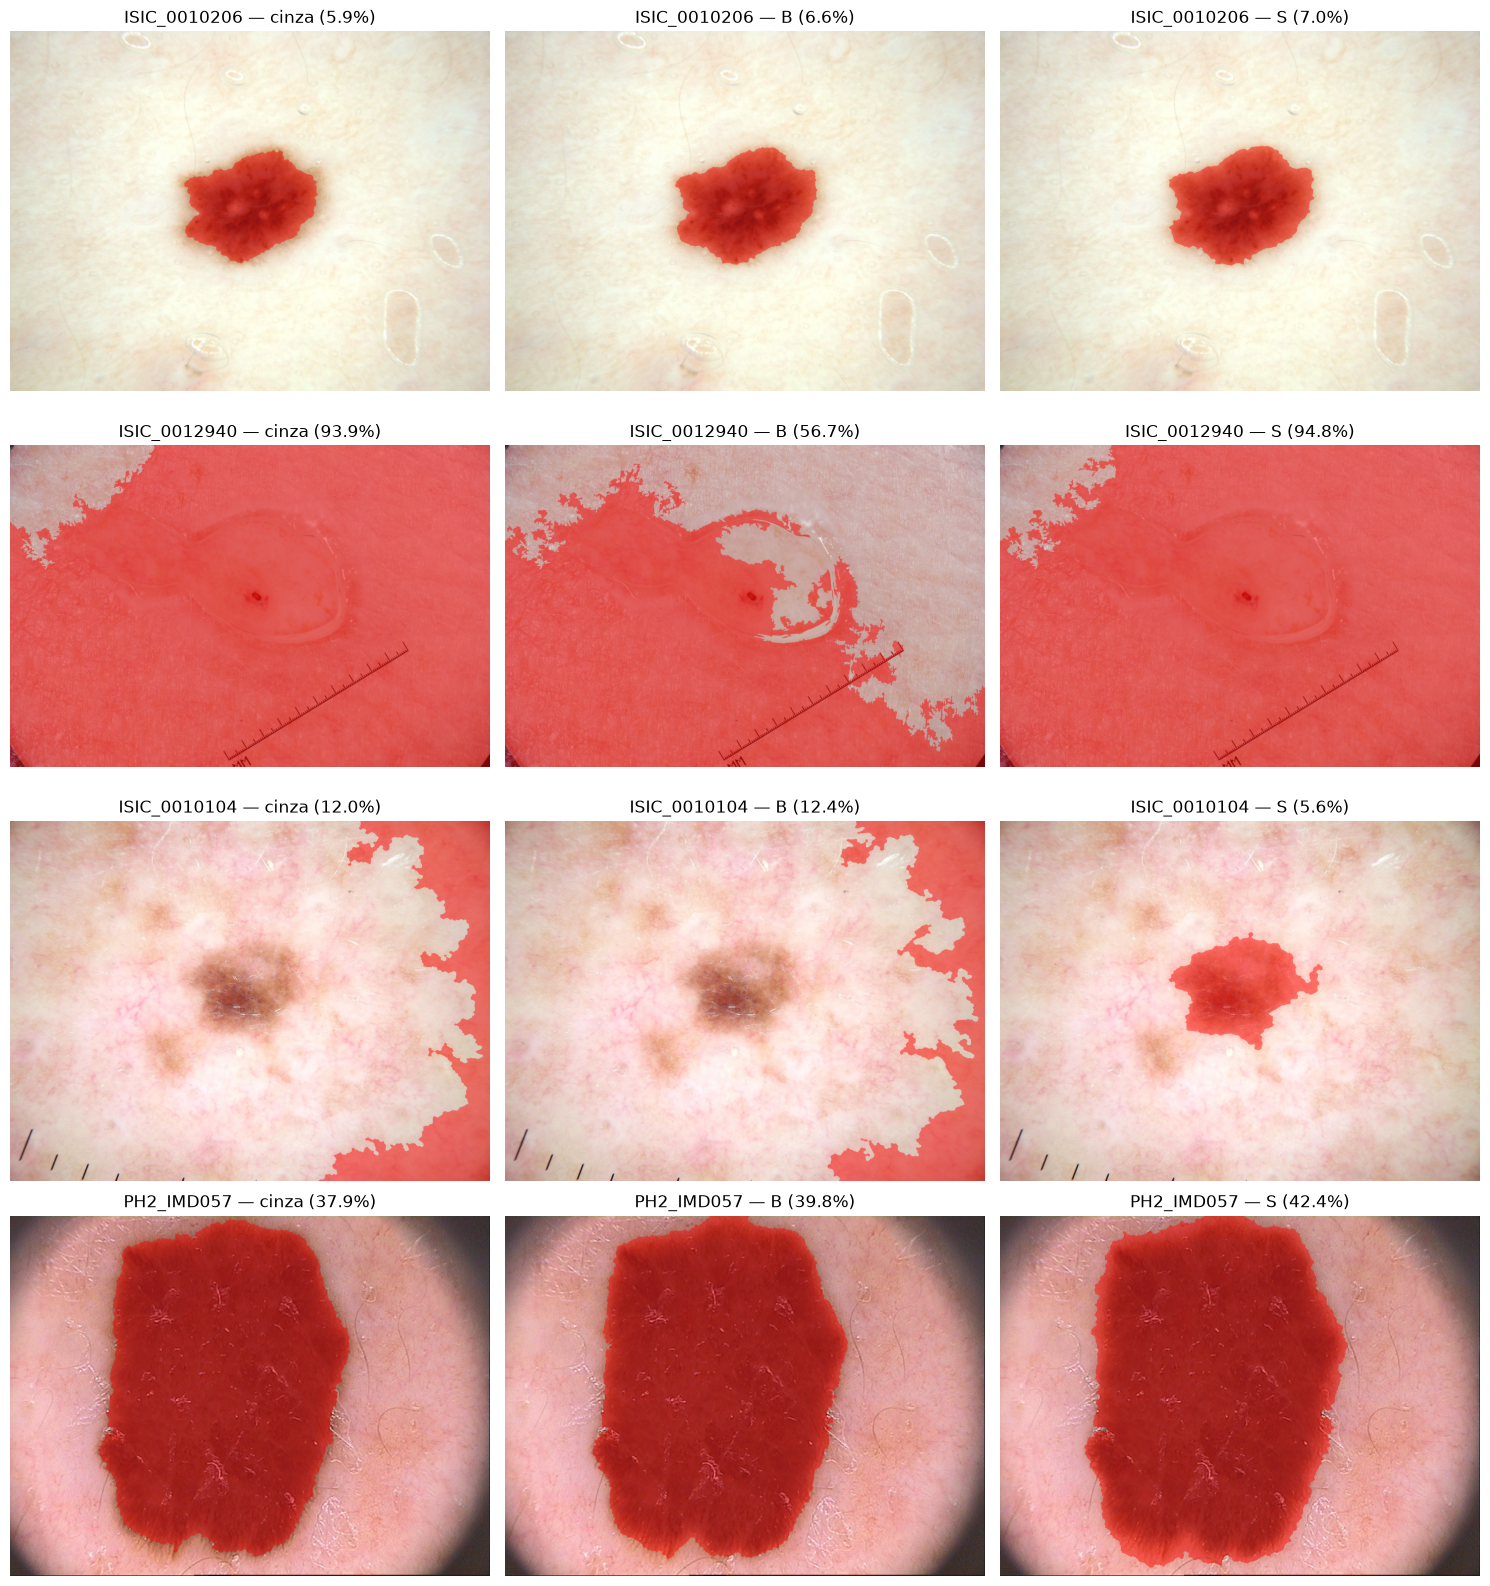

In [4]:
fig, axes = plt.subplots(len(IMAGENS), 3, figsize=(15, 4 * len(IMAGENS)))
for i, nome in enumerate(IMAGENS):
    img = carregar_imagem(PASTA_IMAGENS / nome)
    nome_curto = Path(nome).stem
    for j, (canal, extrair) in enumerate(CANAIS.items()):
        plano = extrair(img)
        t = otsu(plano)
        bruta = binarizar(plano, t, invertida=INVERTIDA[canal])
        final = pos_processar(bruta)
        frac = final.mean() / 255
        axes[i, j].imshow(sobrepor(img, final))
        axes[i, j].set_title(f"{nome_curto} — {canal} ({frac*100:.1f}%)")
        axes[i, j].axis("off")

fig.tight_layout()
fig.savefig(PASTA_RESULTADOS / "segmentadas" / "comparacao_canais.png", bbox_inches="tight", dpi=150)
plt.show()
plt.close(fig)